$\left\{\begin{matrix}
\partial_t \overline{u}(x,t) + a \partial_x \overline{u}(x,t) = 0 ,& \forall (x,t)\in \mathbb{R} \times (0,T) \\
\overline{u}(x,0) = u_{ini}(x) ,& \forall x \in \mathbb{R} \\
\end{matrix}\right.$

si $u_{ini}$ est 1-périodique,i.e.$u_{ini}(x+1)=u_{ini}(x)$ ,alors $\overline{u}(x+1,t) = u_{ini}(x-at+1) = u_{ini}(x-at) =\overline{u}(x,t)$

$\forall x \in \mathbb{R} ,u_{ini}(x+1)=sin(2\pi (x+1))=sin(2\pi x + 2\pi)=sin(2\pi x)cos(2\pi)+cos(2\pi x)sin(2\pi) =sin(2\pi x)=u_{ini}(x)$

In [1]:
import numpy as np
import matplotlib.pyplot as plt 

In [2]:
#introduit les paramètres 
a=1
T=0.75
J=20
lambd = 0.8
L=1

In [35]:
#discrétisation
def u_ini(x):
    return np.sin(2* np.pi *x)

def espaceDiscretise(J,lambd):
    dx = L/J
    dt = lambd * dx
    l_x = np.linspace(0,L-dx,J)
    M = int(T/dt)
    return dx,dt,l_x,M

def méthode(method):
    if (method =='centre'):
        return lambd * a /2 ,1 ,- lambd * a /2
    elif (method =='decentre à gauche' ):
        return lambd * a, 1- lambd * a, 0
    elif (method =='decentre à droite' ):
        return 0, 1 + lambd * a,-lambd * a
    elif (method =='Lax_Friedrichs' ):
        return 1/2 + lambd * a/2, 0, 1/2-lambd * a /2
    elif (method =='Lax_wendroff'):
        return lambd * a /2 +lambd**2 * a**2 / 2, 1 - lambd**2 * a**2 , -lambd * a /2 +lambd**2 * a**2 / 2
    else :
        print('this method is not acceptable') 
        

In [40]:

def schema(dx,dt,l_x,j,M,c_1,c0,c1):##c_1 signifie c-1 pour distinguer c1 , on ne peut pas utiliser c-1 à cause de signe moins
    U_barre = u_ini(l_x-a*M*dt)
    U_schema = u_ini(l_x)

    vd = np.ones(j)
    vsd= np.ones(j-1)
    
    Ah = np.diag(vd)*c0
    np.fill_diagonal(Ah[:-1, 1:],vsd*c1)
    np.fill_diagonal(Ah[1:, :-1],vsd*c_1)
    Ah[0,-1]=c_1
    Ah[-1,0]=c1

    for n in range(M):
        U_schema = np.dot(Ah,U_schema)
        
    return U_barre, U_schema

del_x,del_t,l_x,M =  espaceDiscretise(J,lambd)
c_1,c0,c1=méthode('centre')
U_barre,U_schema=schema(del_x,del_t,l_x,M,c_1,c0,c1)

In [51]:
def graph(J,lambd,method):
    dx,dt,l_x,M =  espaceDiscretise(J,lambd)
    c_1,c0,c1=méthode(method)
    U_barre,U_schema=schema(dx,dt,l_x,J,M,c_1,c0,c1)
    plt.figure(0)
    plt.plot(l_x, U_schema, '.', label='schema '+method)
    plt.plot(l_x, U_barre, label='solution analytique')
    plt.xlabel('Espace')
    plt.ylabel('u')
    plt.legend()
    plt.title('schema '+method +' en T de pas dx ='+str(dx)+' en esapce')
    plt.show()

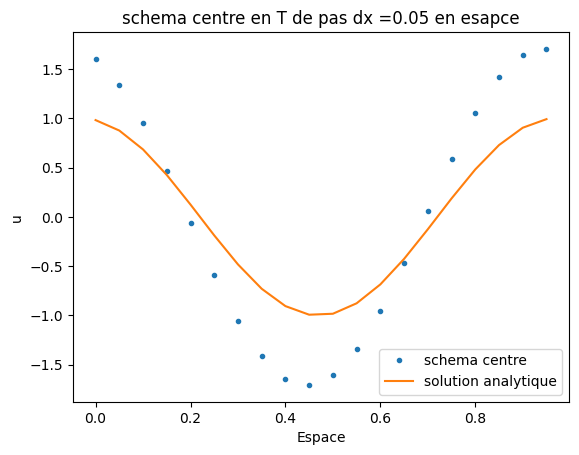

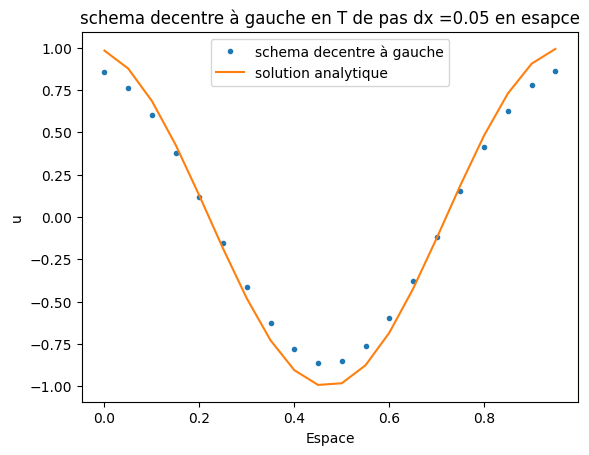

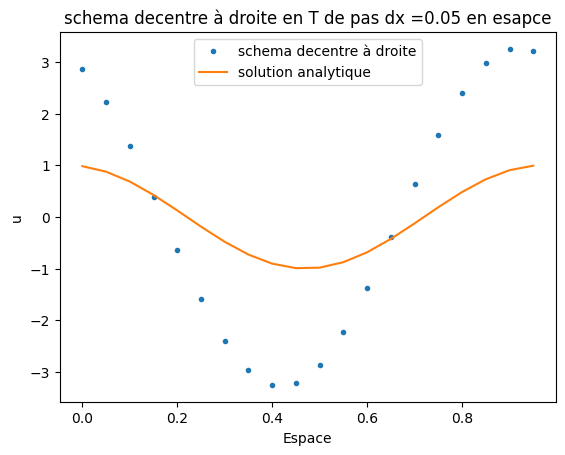

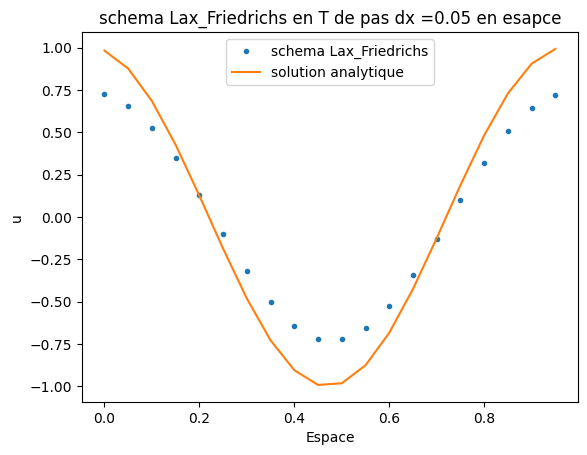

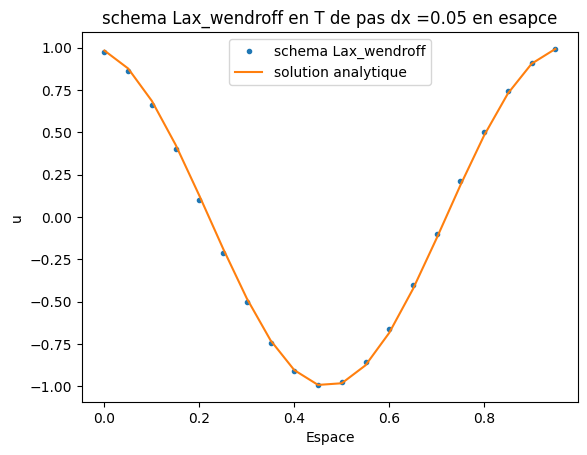

In [52]:
J=20
lambd = 0.8
l_method=['centre','decentre à gauche','decentre à droite','Lax_Friedrichs','Lax_wendroff']
for m in l_method:
    graph(J,lambd,m)

In [7]:
def stable(J,lambd,method):
    dx,dt,l_x,M =  espaceDiscretise(J,lambd)
    c_1,c0,c1=méthode(method)
    
    vd = np.ones(J)
    vsd= np.ones(J-1)
    
    Ah = np.diag(vd)*c0
    np.fill_diagonal(Ah[:-1, 1:],vsd*c1)
    np.fill_diagonal(Ah[1:, :-1],vsd*c_1)
    Ah[0,-1]=c_1
    Ah[-1,0]=c1

    C0 = 0
    for n in range(M):
        if (np.linalg.norm(Ah**n,np.inf)> C0):
            C0 = np.linalg.norm(Ah**n,np.inf)
    return C0

In [8]:
for m in l_method:
    print(stable(J,lambd,m))

20.0
20.0
21859.13811538511
20.0
20.0


In [73]:
def err(dx,dt,l_x,j,M,c_1,c0,c1):##c_1 signifie c-1 pour distinguer c1 , on ne peut pas utiliser c-1 à cause de signe moins
    
    U_schema = u_ini(l_x)

    l_err_inf=np.zeros(M)
    l_err_2=np.zeros(M)

    vd = np.ones(j)
    vsd= np.ones(j-1)
    
    Ah = np.diag(vd)*c0
    np.fill_diagonal(Ah[:-1, 1:],vsd*c1)
    np.fill_diagonal(Ah[1:, :-1],vsd*c_1)
    Ah[0,-1]=c_1
    Ah[-1,0]=c1
    
    for n in range(M):
        U_schema = np.dot(Ah,U_schema)
        U_barre = u_ini(l_x-(n+1)*dt)
        
        l_err_inf[n]=np.linalg.norm(U_barre - U_schema, np.inf)
        l_err_2[n]=np.linalg.norm(U_barre - U_schema, 2)* np.sqrt(dx)
    return U_barre, U_schema,np.max(l_err_2),np.max(l_err_inf)

In [74]:
def graph_err(l_J,lambd,method):
    plt.figure(0)
    l_err_2=np.zeros(len(l_J))
    l_err_inf=np.zeros(len(l_J))
    for j in range(len(l_J)):
        dx,dt,l_x,M =  espaceDiscretise(l_J[j],lambd)
        c_1,c0,c1=méthode(method)
        _,_,err_2,err_inf= err(dx,dt,l_x,l_J[j],M,c_1,c0,c1)
        l_err_2[j]=err_2
        l_err_inf[j]=err_inf
    
    plt.loglog(1/l_J, l_err_2, '.', label='err 2')
    plt.loglog(1/l_J, l_err_inf,'--',  label='err inf')
    plt.xlabel('')
    plt.ylabel('')
    plt.legend()
    plt.title('erreur du schema '+method)
    plt.show()

In [75]:
l_J=np.array([25,50,100,200])


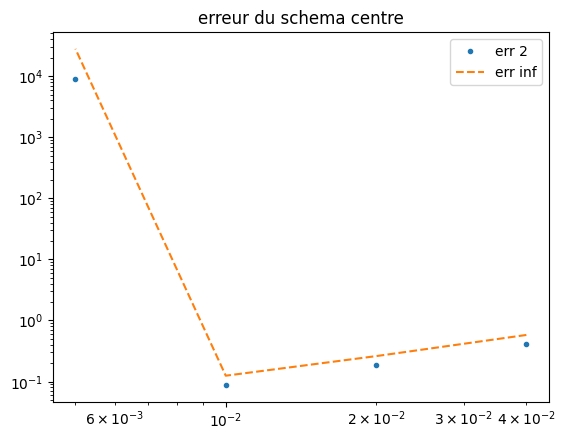

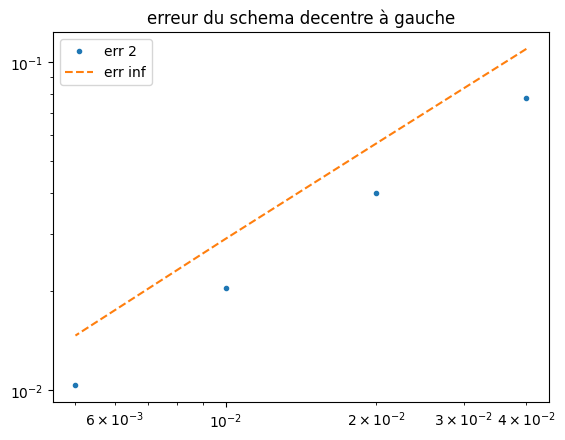

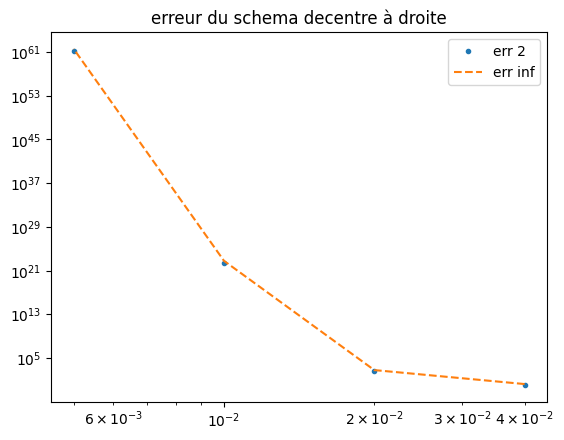

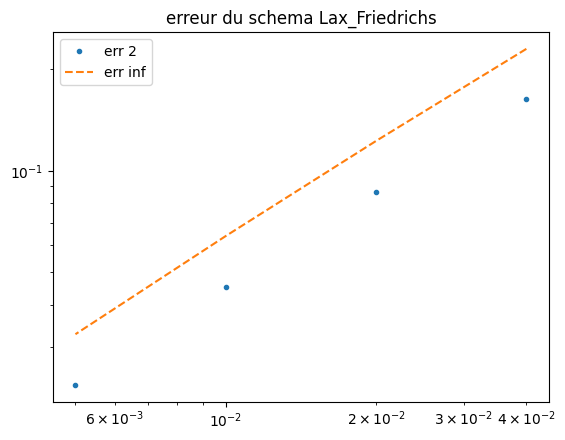

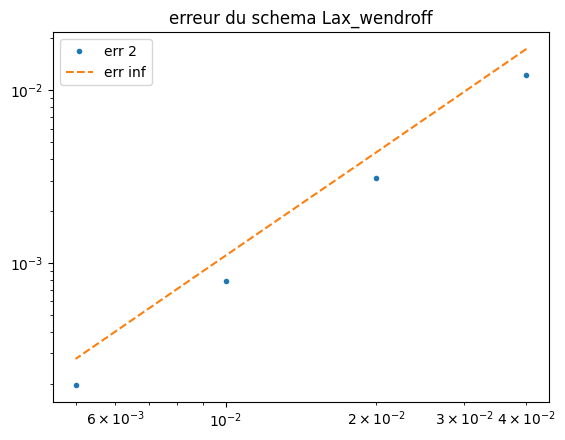

In [76]:
for m in l_method:
    graph_err(l_J,lambd,m)